# Walkthrough: from battle simulation to bet sizing

This notebook runs the pipeline end to end on the **Final** (Oct 19, 2026), where the crowd gave Mirror Fruity 14% and Saurians 25% and the model gave them 91% and 87%. Both won.

1. **Simulate** the match many times under parameter uncertainty → a win probability with a standard error.
2. **Price** it: the crowd's support rate is an implied probability, the multiplier is the payout.
3. **Size** the bet: why max-Sharpe fails here, and the mean-variance frontier that replaced it.
4. **Evaluate** without look-ahead bias.

Everything runs on the Python standard library plus matplotlib, in under a minute.

In [1]:
import math, random, sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
from pvd import sim, strategies, evaluate

## 1. Simulate

`sim.run` plays one battle on the grid: targeting, movement, AoE, crowd control, elemental reactions, overtime. Mechanics that can't be read off a unit card are drawn from the **ABC posterior** fitted to 12 replays (`pvd/calibrate.py`), so each run uses a different plausible set of parameters. The spread of outcomes carries the model's uncertainty, not only the battle's randomness.

In [2]:
units, places, matches = sim.load()
posterior = sim.load_posterior()
counts = sim.replay_counts()
final = [m for m in matches if m["round"] == "Final"]

random.seed(0)
N = 1000
for m in final:
    plist = sim.match_units(places, "Final", m["match"])
    ids = sorted({p["unit_id"] for p in plist})
    wins = sum(sim.run(units, plist, *sim.draw_params(ids, posterior, counts))[0] == "L" for _ in range(N))
    p = wins / N
    print(f"{m['left_team']:24s} vs {m['right_team']:26s} P(left) = {p:.3f} ± {1.96 * math.sqrt(p * (1 - p) / N):.3f}"
          f"   crowd {m['left_support_pct']}%   logged live call {float(m['model_p_left']):.3f}")

Mirror Fruity Order      vs What Does the Ninken Say?  P(left) = 0.910 ± 0.018   crowd 14%   logged live call 0.912


Saurians Are the Cutest  vs Reserve Grenadier Squad    P(left) = 0.885 ± 0.020   crowd 25%   logged live call 0.867


## 2. Price

A right pick pays `emblems × M`, a wrong pick still pays `emblems × 10`. The expected value per emblem is `p·M + (1 − p)·10`, and a side is worth backing when `p` beats its break-even. The crowd's ×200 on Fruity implies about 14%; the model says about 90%.

In [3]:
args = strategies.parse_args(["Final", "--pool", "200", "--linw", "0.65,0.65"])
games = strategies.load_games(args)   # live model pooled with the crowd at the trust weight used on the day
for g in games:
    a, b = g["sides"]
    be = (b["M"] - 10) / ((a["M"] - 10) + (b["M"] - 10))
    for s in (a, b):
        print(f"{s['team'][:26]:26s} p={s['p']:.2f}  x{s['M']:<4g} EV/emblem {strategies.leg(s, 1)[0]:6.1f}")
    print(f"  break-even P({a['team'][:14]}) = {be:.3f}\n")

Mirror Fruity Order        p=0.64  x200  EV/emblem  131.9
What Does the Ninken Say?  p=0.36  x25   EV/emblem   15.4
  break-even P(Mirror Fruity ) = 0.073

Saurians Are the Cutest    p=0.65  x105  EV/emblem   71.8
Reserve Grenadier Squad    p=0.35  x30   EV/emblem   17.0
  break-even P(Saurians Are t) = 0.174



## 3. Size: why not Sharpe?

The standard risk-adjusted yardstick fails on this problem. With a fixed payout floor, a binary bet's Sharpe ratio is `sqrt(p / (1 − p))`: **the multiplier cancels**. Cutting a bet's payout makes it strictly worse and leaves its Sharpe untouched. And because the max-Sharpe portfolio weights bets by excess EV / variance, it pushes stake *away* from big-payout bets. (Full argument: `docs/DECISIONS.md` §1.)

In [4]:
for M in (20, 50, 105, 200):
    s = dict(p=0.6, M=M)
    print(f"p=0.60  x{M:<4d} EV/emblem {strategies.leg(s, 1)[0]:6.1f}   Sharpe {strategies.sharpe(s, 1):.3f}")

p=0.60  x20   EV/emblem   16.0   Sharpe 1.225
p=0.60  x50   EV/emblem   34.0   Sharpe 1.225
p=0.60  x105  EV/emblem   67.0   Sharpe 1.225
p=0.60  x200  EV/emblem  124.0   Sharpe 1.225


Sharpe is the right yardstick when a portfolio can be levered to a risk target. Stakes here are capped and can't be levered, so the objective is the **certainty equivalent** directly:

$$\text{CE} = \mathbb{E}[X] - \frac{\lambda}{2}\,\text{Var}[X]$$

λ is risk aversion: λ = 0 is pure EV (Strategy B, "Dino"), and Strategy A ("Shado") ran λ = 2.1·10⁻⁴ all event. Sweeping λ traces the efficient frontier of allocations for the Final:

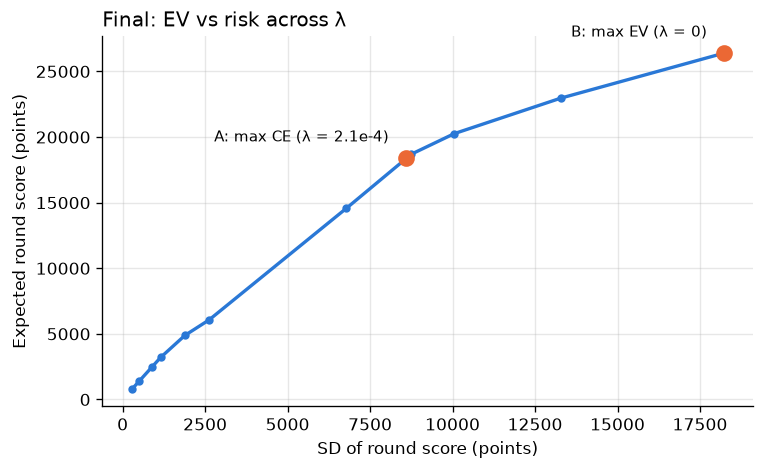

λ=0       EV   26388  SD  18220  200 on Mirror Fruity Order
λ=0.00021 EV   18396  SD   8575  67 on Mirror Fruity Order, 133 on Saurians Are the Cutest


In [5]:
lams = [0] + [10 ** (x / 4) for x in range(-24, -7)]
frontier = []
for lam in lams:
    ce, ev, var, picks = strategies.best_ce(games, lam, 200)
    frontier.append((var ** 0.5, ev, lam, picks))

fig, ax = plt.subplots(figsize=(7, 4), dpi=120)
ax.plot([f[0] for f in frontier], [f[1] for f in frontier], color="#2a78d6", lw=2, marker="o", ms=4)
for lam, label in ((0, "B: max EV (λ = 0)"), (2.1e-4, "A: max CE (λ = 2.1e-4)")):
    ce, ev, var, picks = strategies.best_ce(games, lam, 200)
    ax.plot(var ** 0.5, ev, "o", ms=9, color="#eb6834", zorder=3)
    ax.annotate(label, (var ** 0.5, ev), xytext=(-10, 10), textcoords="offset points", ha="right", fontsize=9)
ax.set_xlabel("SD of round score (points)")
ax.set_ylabel("Expected round score (points)")
ax.set_title("Final: EV vs risk across λ", loc="left")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.grid(alpha=0.3)
plt.show()

for lam in (0, 2.1e-4):
    ce, ev, var, picks = strategies.best_ce(games, lam, 200)
    print(f"λ={lam:<7g} EV {ev:7.0f}  SD {var ** 0.5:6.0f}  " + ", ".join(f"{e} on {t}" for e, t, _ in picks if e))

On the day, Shado played 67 Fruity + 133 Saurians (EV ≈ 18,400) and Dino 200 Fruity (EV ≈ 26,400). Both underdogs won: +27,365 and +40,000.

## 4. Evaluate without look-ahead bias

A backtest is only as honest as what it was allowed to know. Each row below lets in more information from after the match. The **strict walk-forward** (`pvd/backtest/walk_forward_strict.py`) withholds every replay-measured value and replay-discovered mechanic until the round after its source replay. The leakier backtests look much better, and that improvement is the bias, not skill.

In [6]:
print(f"{'Predictor':26s} {'Look-ahead':24s} {'Correct':>8s} {'Brier':>7s}")
for k, label, _, bias in evaluate.PREDICTORS:
    right, brier = evaluate.SCORES[k]
    print(f"{label.strip('*'):26s} {bias:24s} {right:>4d}/{len(evaluate.scored)} {brier:7.3f}")

Predictor                  Look-ahead                Correct   Brier
Live model                 None                       11/14   0.234
Strict walk-forward        Minimal                     9/14   0.210
Walk-forward (v8 priors)   Structural                 13/14   0.106
Leave-one-out CV           Structural + parameter     11/14   0.114
Crowd                      None                        6/14   0.336


Brier score is the mean squared error of the probability: 0 is perfect, 0.25 is always saying 50%. The live model was right 11 / 14 against the crowd's 6 / 14. If both were coin flips, a gap of 5 or more would happen about 4% of the time: evidence of a real edge, on a small sample.